# Step 4 — Similarity vs. Retrieval Experiment

**Project:** *When Memories Compete: How Similarity Affects Memory Retrieval in Hopfield Networks*

**Question:** across many groups of 5 stored handwritten images, how does a group's **mean pairwise overlap** relate to
(a) whether the stored images are exact stable states, and (b) whether corrupted images are retrieved exactly?

**Design (approved):**
- 84 groups of 5 real images (5 different digits), sampled **stratified by mean overlap**: 7 bins of width 0.05 from 0.30 to 0.65, 12 groups per bin
- Corruption levels **0% (clean), 5%, 10%, 20%**, with **20 independent trials per image per level** (400 recalls per group)
- Hopfield learning and update rules **unchanged** (`src/hopfield.py`, verified in notebook 03)
- **Unit of analysis = the group.** Trials are summarised within each group first, and all statistics use one value per group.
- The two hand-picked groups from notebook 02 are run with the same protocol but **kept out of all statistics**.

Not part of this notebook: the human-memory comparison and the final write-up.

In [2]:
import sys, json, time
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.optdigits import load_optdigits
from src.hopfield import train_hebbian, recall, is_fixed_point, corrupt, overlap   # rules unchanged

RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(exist_ok=True)

images, labels = load_optdigits()
N = 32 * 32
patterns = 2.0 * images.reshape(len(images), N) - 1.0     # ±1, float64 (no overflow possible)
M_all = patterns @ patterns.T / N                         # all pairwise overlaps, float64
print("patterns:", patterns.shape, "| overlap matrix:", M_all.shape, M_all.dtype)

patterns: (946, 1024) | overlap matrix: (946, 946) float64


## 1. Settings and random seeds

Everything random comes from two fixed seeds:
- `SAMPLING_SEED` decides which groups are sampled.
- `TRIAL_SEED` is split with `np.random.SeedSequence(TRIAL_SEED).spawn(n)` into **one independent stream per group**.
  Group *g* always gets the same stream, so any single group can be re-run on its own and give identical results:
  `np.random.default_rng(np.random.SeedSequence(TRIAL_SEED).spawn(n_groups)[g])`.

The full experiment takes a few minutes. With `RECOMPUTE = False` the notebook loads the saved results from `results/` if they exist.

In [3]:
RECOMPUTE = False          # True = rerun the full experiment, even if saved results exist

CONFIG = dict(
    SAMPLING_SEED      = 2026,
    TRIAL_SEED         = 2027,
    HANDPICKED_SEED    = 2028,
    N_CANDIDATES       = 200_000,                       # random groups generated before stratifying
    GROUP_SIZE         = 5,
    BIN_EDGES          = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65],
    GROUPS_PER_BIN     = 12,
    CORRUPTION_LEVELS  = [0.00, 0.05, 0.10, 0.20],
    TRIALS_PER_IMAGE   = 20,
    MAX_SWEEPS         = 100,                           # same default as src/hopfield.recall
    BOOTSTRAP_SAMPLES  = 2000,
)
LEVELS = CONFIG["CORRUPTION_LEVELS"]
G = CONFIG["GROUP_SIZE"]
CONFIG

{'SAMPLING_SEED': 2026,
 'TRIAL_SEED': 2027,
 'HANDPICKED_SEED': 2028,
 'N_CANDIDATES': 200000,
 'GROUP_SIZE': 5,
 'BIN_EDGES': [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65],
 'GROUPS_PER_BIN': 12,
 'CORRUPTION_LEVELS': [0.0, 0.05, 0.1, 0.2],
 'TRIALS_PER_IMAGE': 20,
 'MAX_SWEEPS': 100,
 'BOOTSTRAP_SAMPLES': 2000}

## 2. The image pool: "typical" images

**Definition (same as notebook 02).** For each image $i$ with digit label $d_i$:

$$\text{typicality}_i = \frac{1}{n_{d_i} - 1} \sum_{j \neq i,\; d_j = d_i} m(\xi^i, \xi^j)$$

That is, the mean raw ±1 overlap of image $i$ with every **other** image of the same digit.
An image is **typical** if its typicality is **at or above the median typicality of its own digit**.
This keeps the more typical half of each digit: **476 of 946 images**.

**Why:** without this filter the highest-overlap groups were dominated by thick, blob-like images that are barely readable as digits (see notebook 02).

**Scope:** all results in this notebook apply to **groups drawn from this typical subset**, not to the whole dataset or to arbitrary handwriting.

In [4]:
typicality = np.zeros(len(labels))
for i in range(len(labels)):
    same_digit = labels == labels[i]
    same_digit[i] = False
    typicality[i] = M_all[i, same_digit].mean()

in_pool = np.zeros(len(labels), dtype=bool)
for d in range(10):
    idx_d = np.where(labels == d)[0]
    in_pool[idx_d] = typicality[idx_d] >= np.median(typicality[idx_d])
pool = np.where(in_pool)[0]
pool_by_digit = [pool[labels[pool] == d] for d in range(10)]

print(f"typical pool: {len(pool)} of {len(labels)} images")
print("per digit   :", {d: len(p) for d, p in enumerate(pool_by_digit)})
assert len(pool) == 476   # same pool as notebook 02

typical pool: 476 of 946 images
per digit   : {0: 44, 1: 49, 2: 46, 3: 43, 4: 57, 5: 54, 6: 44, 7: 48, 8: 46, 9: 45}


## 3. Sampling the groups (stratified by mean overlap)

1. Generate `N_CANDIDATES` random groups: choose 5 different digits, then one random typical image of each.
2. Score each group by its **mean pairwise overlap** (the mean of its 10 pairwise overlaps). Remove duplicate groups.
3. Put each group in a bin: [0.30, 0.35), [0.35, 0.40), …, [0.60, 0.65).
4. Draw **12 groups at random from each bin** without replacement → 84 groups.

Plain random sampling would put most groups near 0.45. Stratifying spreads them evenly across the overlap range, and every group is still a random draw.
The extreme bins contain few candidates (only a few dozen at 0.60–0.65), so their 12 groups are drawn from a small set.

In [5]:
def mean_pairwise_overlap(idx):
    return float(np.mean([M_all[a, b] for a, b in combinations(idx, 2)]))

samp_rng = np.random.default_rng(CONFIG["SAMPLING_SEED"])
edges = np.array(CONFIG["BIN_EDGES"])
n_bins = len(edges) - 1

# 1-2. Random candidate groups, deduplicated (a group = sorted tuple of image indices)
candidates = {}
for _ in range(CONFIG["N_CANDIDATES"]):
    digits = samp_rng.choice(10, size=G, replace=False)
    idx = tuple(sorted(int(samp_rng.choice(pool_by_digit[d])) for d in digits))
    if idx not in candidates:
        candidates[idx] = mean_pairwise_overlap(idx)
cand_idx = list(candidates.keys())
cand_m = np.array(list(candidates.values()))

# 3. Bin index for each candidate (-1 = outside the bin range)
cand_bin = np.digitize(cand_m, edges) - 1
cand_bin[(cand_m < edges[0]) | (cand_m >= edges[-1])] = -1

# 4. Draw GROUPS_PER_BIN from each bin. Iterate over bins in order, so the result is reproducible.
groups = []
for b in range(n_bins):
    members = np.where(cand_bin == b)[0]
    assert len(members) >= CONFIG["GROUPS_PER_BIN"], f"bin {b} has only {len(members)} candidates"
    chosen = samp_rng.choice(members, size=CONFIG["GROUPS_PER_BIN"], replace=False)
    for c in sorted(chosen):
        groups.append(dict(bin=b, idx=np.array(cand_idx[c]), mean_overlap=cand_m[c]))

for g_id, g in enumerate(groups):
    g["group_id"] = g_id
    g["digits"] = labels[g["idx"]]

bin_labels = [f"{edges[b]:.2f}–{edges[b+1]:.2f}" for b in range(n_bins)]
print(f"{len(cand_idx):,} unique candidate groups")
print("candidates per bin:", dict(zip(bin_labels, np.bincount(cand_bin[cand_bin >= 0], minlength=n_bins))))
print("sampled groups    :", len(groups))

200,000 unique candidate groups
candidates per bin: {'0.30–0.35': 108, '0.35–0.40': 8024, '0.40–0.45': 66750, '0.45–0.50': 94046, '0.50–0.55': 29008, '0.55–0.60': 2048, '0.60–0.65': 16}
sampled groups    : 84


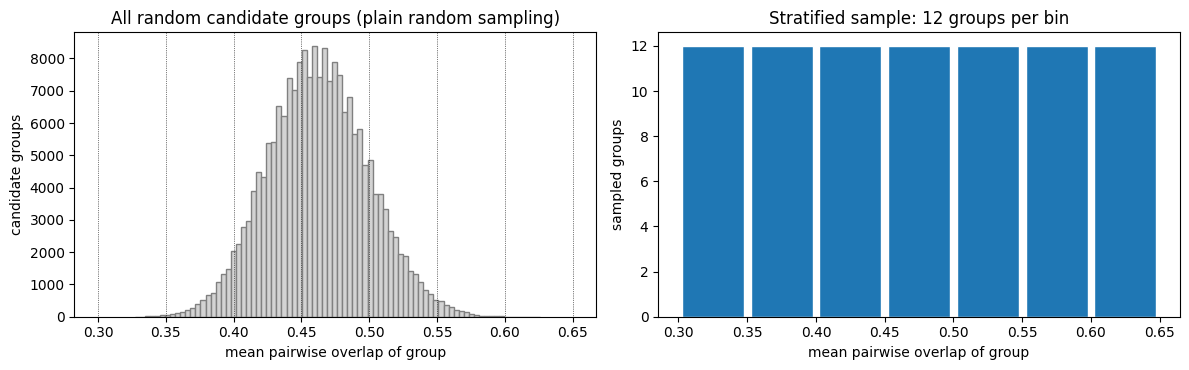

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(cand_m, bins=80, color="lightgray", edgecolor="gray")
for e in edges:
    axes[0].axvline(e, color="k", lw=0.5, ls=":")
axes[0].set_xlabel("mean pairwise overlap of group"); axes[0].set_ylabel("candidate groups")
axes[0].set_title("All random candidate groups (plain random sampling)")

sampled_m = np.array([g["mean_overlap"] for g in groups])
axes[1].hist(sampled_m, bins=edges, color="tab:blue", edgecolor="white", rwidth=0.9)
axes[1].set_xlabel("mean pairwise overlap of group"); axes[1].set_ylabel("sampled groups")
axes[1].set_title("Stratified sample: 12 groups per bin")
plt.tight_layout()
plt.show()

### Two limits on what the sample can show

**Image reuse.** 84 groups × 5 = 420 image slots come from a pool of 476 images, and the extreme bins draw on few candidates, so some images appear in several groups.
Groups are sampled independently, but groups that share images are **not fully independent data points**. The confidence intervals below treat groups as independent, so they are somewhat optimistic.

**Digit composition.** Overlap is not the only thing that differs between bins: some digits appear more often in high-overlap groups.
Any relationship we find is an **association** between overlap and retrieval, and could partly reflect *which* digits are involved.

image slots: 420, distinct images used: 265
images used once: 163, used 2+ times: 102, max uses of one image: 9


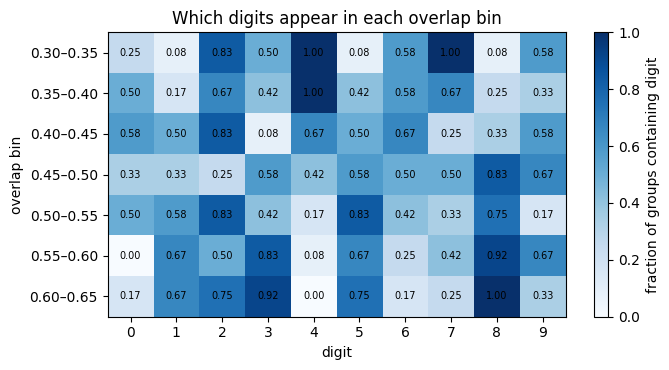

In [7]:
all_slots = np.concatenate([g["idx"] for g in groups])
uses = np.bincount(all_slots, minlength=len(labels))[pool]
print(f"image slots: {len(all_slots)}, distinct images used: {np.sum(uses > 0)}")
print(f"images used once: {np.sum(uses == 1)}, used 2+ times: {np.sum(uses >= 2)}, max uses of one image: {uses.max()}")

# Digit composition per bin: fraction of groups in the bin that contain each digit
comp = np.zeros((n_bins, 10))
for g in groups:
    comp[g["bin"], g["digits"]] += 1
comp /= CONFIG["GROUPS_PER_BIN"]

plt.figure(figsize=(7, 3.8))
plt.imshow(comp, cmap="Blues", vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="fraction of groups containing digit")
for b in range(n_bins):
    for d in range(10):
        plt.text(d, b, f"{comp[b, d]:.2f}", ha="center", va="center", fontsize=7)
plt.xticks(range(10)); plt.yticks(range(n_bins), bin_labels)
plt.xlabel("digit"); plt.ylabel("overlap bin")
plt.title("Which digits appear in each overlap bin")
plt.tight_layout()
plt.show()

## 4. Per-group protocol and outcome categories

For each group: store the 5 images with `train_hebbian`. Then, for each corruption level (0%, 5%, 10%, 20%), each image and each of 20 trials:
flip exactly round(level × 1024) random pixels of the image, run `recall` to convergence or to `MAX_SWEEPS`, and classify the final state.

**Outcome categories.** These are checked **in this order**, and the first that applies is used, so they are **mutually exclusive**:

| # | category | definition |
|---|---|---|
| 1 | `not_converged` | `recall` hit `MAX_SWEEPS` and the state was still changing. **Checked first**, so an unfinished state is never classified. |
| 2 | `correct` | the final state equals the **target** image, pixel for pixel |
| 3 | `wrong_memory` | the final state equals **another of the 4 stored images**, pixel for pixel |
| 4 | `mirror` | the final state equals the **inverse** (−ξ) of any stored image, pixel for pixel |
| 5 | `other_attractor` | any other fixed point, e.g. a blend of several images. **Never counted as a stored memory.** |

**Retrieval accuracy** of a group at a level = the fraction of its 100 trials (5 images × 20) in category `correct`.

**Clean stability** = the number of the 5 stored images that are exact fixed points (`is_fixed_point == 1.0`).
The 0% level is the same test done by actually running recall: each clean trial still uses a random update order.
An image is retrieved exactly from a clean start **if and only if** it is a fixed point. The reason is that every flip strictly lowers the energy, so the state can never return to where it started.
The code checks that the two measures agree.

In [8]:
CATEGORIES = ["correct", "wrong_memory", "mirror", "other_attractor", "not_converged"]

def classify(res, target_pos, stored):
    """Return exactly one category for a recall result (see table above)."""
    if not res["converged"]:                                   # 1. checked before anything else
        return "not_converged"
    s = res["state"]
    if np.array_equal(s, stored[target_pos]):                  # 2.
        return "correct"
    for k in range(len(stored)):                               # 3.
        if k != target_pos and np.array_equal(s, stored[k]):
            return "wrong_memory"
    for k in range(len(stored)):                               # 4.
        if np.array_equal(s, -stored[k]):
            return "mirror"
    return "other_attractor"                                   # 5.

def run_group(idx, rng):
    """Run the full protocol on one group. Returns (list of trial rows, stability info)."""
    stored = patterns[idx]
    # The categories can only be exclusive if no two stored images are equal or inverses of each other.
    for a, b in combinations(range(len(idx)), 2):
        assert not np.array_equal(stored[a], stored[b]) and not np.array_equal(stored[a], -stored[b])

    W = train_hebbian(stored)
    stable = np.array([is_fixed_point(W, p) == 1.0 for p in stored])

    rows = []
    for level in LEVELS:
        for pos in range(len(idx)):
            for t in range(CONFIG["TRIALS_PER_IMAGE"]):
                start = corrupt(stored[pos], level, rng)
                res = recall(W, start, rng, max_sweeps=CONFIG["MAX_SWEEPS"])
                rows.append(dict(
                    image_pos=pos, image_index=int(idx[pos]), digit=int(labels[idx[pos]]),
                    level=level, trial=t,
                    outcome=classify(res, pos, stored),
                    final_overlap_target=overlap(res["state"], stored[pos]),
                    sweeps=res["sweeps"], converged=res["converged"],
                ))
    return rows, stable

## 5. Run the experiment (or load saved results)

Saved files in `results/`:
- `step4_trials.csv`: one row per recall trial (84 groups × 400 = 33,600 rows)
- `step4_groups.csv`: one row per group: overlap, bin, images, digits, clean stability, outcome proportions per level
- `step4_handpicked_trials.csv`, `step4_handpicked_groups.csv`: the two notebook-02 groups, kept separate
- `step4_config.json`: all settings and seeds

In [9]:
TRIALS_CSV = RESULTS_DIR / "step4_trials.csv"
GROUPS_CSV = RESULTS_DIR / "step4_groups.csv"
HP_TRIALS_CSV = RESULTS_DIR / "step4_handpicked_trials.csv"
HP_GROUPS_CSV = RESULTS_DIR / "step4_handpicked_groups.csv"
CONFIG_JSON = RESULTS_DIR / "step4_config.json"

HANDPICKED = {   # from notebook 02 (greedy search); NOT part of the statistics
    "hand_LOW":  np.array([226, 813, 365, 386, 127]),
    "hand_HIGH": np.array([608, 629, 877, 534, 689]),
}

def summarise(trials_df, group_info):
    """One row per group: clean stability + proportion of each outcome at each level."""
    rows = []
    for gi in group_info:
        t = trials_df[trials_df.group_id == gi["group_id"]]
        row = {k: v for k, v in gi.items()}
        for level in LEVELS:
            tl = t[t.level == level]
            props = tl.outcome.value_counts(normalize=True)
            for cat in CATEGORIES:
                row[f"{cat}_{int(level*100)}"] = float(props.get(cat, 0.0))
            row[f"mean_final_overlap_{int(level*100)}"] = tl.final_overlap_target.mean()
        rows.append(row)
    return pd.DataFrame(rows)

def run_many(group_list, seed):
    seeds = np.random.SeedSequence(seed).spawn(len(group_list))
    all_rows, info = [], []
    for g, ss in zip(group_list, seeds):
        rng = np.random.default_rng(ss)
        rows, stable = run_group(g["idx"], rng)
        for r in rows:
            r["group_id"] = g["group_id"]
        all_rows += rows
        info.append(dict(group_id=g["group_id"], bin=g.get("bin", -1), mean_overlap=g["mean_overlap"],
                         images=" ".join(map(str, g["idx"])), digits=" ".join(map(str, labels[g["idx"]])),
                         n_stable=int(stable.sum())))
    return pd.DataFrame(all_rows), info

def config_matches_saved():
    if not CONFIG_JSON.exists():
        return False
    return json.loads(CONFIG_JSON.read_text()) == json.loads(json.dumps(CONFIG))

if RECOMPUTE or not (TRIALS_CSV.exists() and GROUPS_CSV.exists() and config_matches_saved()):
    t0 = time.time()
    trials, info = run_many(groups, CONFIG["TRIAL_SEED"])
    group_df = summarise(trials, info)

    hp_list = [dict(group_id=name, idx=idx, mean_overlap=mean_pairwise_overlap(idx)) for name, idx in HANDPICKED.items()]
    hp_trials, hp_info = run_many(hp_list, CONFIG["HANDPICKED_SEED"])
    hp_df = summarise(hp_trials, hp_info)

    trials.to_csv(TRIALS_CSV, index=False);       group_df.to_csv(GROUPS_CSV, index=False)
    hp_trials.to_csv(HP_TRIALS_CSV, index=False); hp_df.to_csv(HP_GROUPS_CSV, index=False)
    CONFIG_JSON.write_text(json.dumps(CONFIG, indent=2))
    print(f"experiment ran in {time.time() - t0:.0f} s; results saved to {RESULTS_DIR}")
else:
    trials, group_df = pd.read_csv(TRIALS_CSV), pd.read_csv(GROUPS_CSV)
    hp_trials, hp_df = pd.read_csv(HP_TRIALS_CSV), pd.read_csv(HP_GROUPS_CSV)
    print("loaded saved results from", RESULTS_DIR)

# The saved groups must be the groups sampled above (same seeds -> same groups)
assert np.allclose(group_df.mean_overlap.values, [g["mean_overlap"] for g in groups])
print(f"{len(group_df)} groups, {len(trials):,} trials")

loaded saved results from /Users/blessingngwechelseandeh/Desktop/hopfield-memory/results
84 groups, 33,600 trials


### Sanity checks on the results

In [10]:
per_group = CONFIG["TRIALS_PER_IMAGE"] * G * len(LEVELS)
assert len(trials) == len(group_df) * per_group, "unexpected number of trials"
assert set(trials.outcome) <= set(CATEGORIES)

# Mutually exclusive and complete: the outcome proportions of each group/level add up to 1
for level in LEVELS:
    total = sum(group_df[f"{c}_{int(level*100)}"] for c in CATEGORIES)
    assert np.allclose(total, 1.0)

# 0% accuracy must equal the clean-stability fraction (fixed point <=> exact clean retrieval)
assert np.allclose(group_df["correct_0"], group_df["n_stable"] / G), "clean recall disagrees with fixed-point test"

# correct must mean an exact match, so the final overlap must be exactly 1
assert np.all(trials.loc[trials.outcome == "correct", "final_overlap_target"] == 1.0)

print("non-converged trials:", int((trials.outcome == "not_converged").sum()))
print("max sweeps used     :", int(trials.sweeps.max()), "of", CONFIG["MAX_SWEEPS"])
print("All result checks passed.")

non-converged trials: 0
max sweeps used     : 5 of 100
All result checks passed.


## 6. Results: retrieval accuracy and clean stability vs. group overlap

Each dot is **one group**: its mean overlap and its accuracy, averaged over its 100 trials at that level.
Black lines show the **mean across the 12 groups in each bin**, with **bootstrap 95% confidence intervals** made by resampling groups, not trials.
Stars mark the two hand-picked groups, which are **excluded** from bin means and statistics.

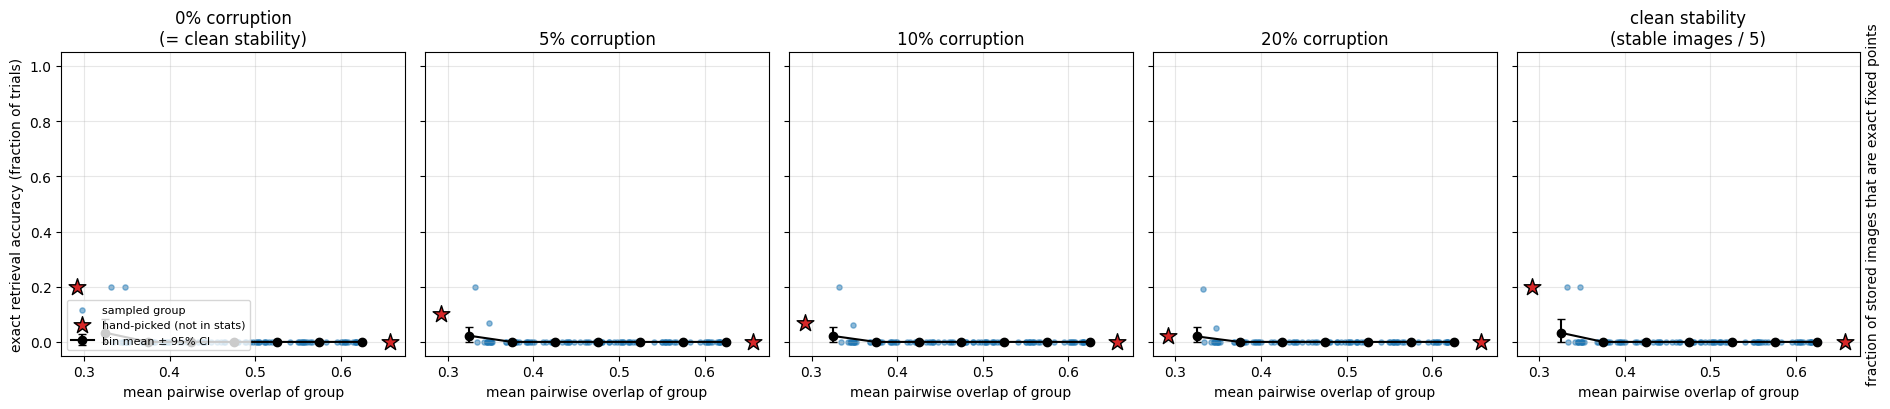

In [11]:
boot_rng = np.random.default_rng(CONFIG["SAMPLING_SEED"] + 1)
B = CONFIG["BOOTSTRAP_SAMPLES"]

def bootstrap_ci_mean(x):
    x = np.asarray(x)
    means = boot_rng.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

bin_centers = (edges[:-1] + edges[1:]) / 2
level_cols = [f"correct_{int(l*100)}" for l in LEVELS]
titles = ["0% corruption\n(= clean stability)", "5% corruption", "10% corruption", "20% corruption"]

fig, axes = plt.subplots(1, len(LEVELS) + 1, figsize=(19, 4.2), sharey=True)
jitter = np.random.default_rng(0).uniform(-0.004, 0.004, len(group_df))   # small x-jitter for visibility only

panels = [(c, t) for c, t in zip(level_cols, titles)] + [("stable_frac", "clean stability\n(stable images / 5)")]
group_df["stable_frac"] = group_df["n_stable"] / G
hp_df["stable_frac"] = hp_df["n_stable"] / G

for ax, (col, title) in zip(axes, panels):
    ax.scatter(group_df.mean_overlap + jitter, group_df[col], s=14, alpha=0.5, color="tab:blue", label="sampled group")
    means, lo, hi = [], [], []
    for b in range(n_bins):
        vals = group_df.loc[group_df.bin == b, col].values
        means.append(vals.mean()); l, h = bootstrap_ci_mean(vals); lo.append(l); hi.append(h)
    means, lo, hi = map(np.array, (means, lo, hi))
    ax.errorbar(bin_centers, means, yerr=[means - lo, hi - means], color="k", marker="o", capsize=3, label="bin mean ± 95% CI")
    ax.scatter(hp_df.mean_overlap, hp_df[col], marker="*", s=160, color="tab:red", edgecolor="k", zorder=5,
               label="hand-picked (not in stats)")
    ax.set_title(title); ax.set_xlabel("mean pairwise overlap of group")
    ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
axes[0].set_ylabel("exact retrieval accuracy (fraction of trials)")
axes[-1].set_ylabel("fraction of stored images that are exact fixed points")
axes[-1].yaxis.set_label_position("right")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### Rank correlation (group level)

For each level: **Spearman ρ** between group mean overlap and group accuracy (n = 84 groups), with a bootstrap 95% CI from resampling groups.
Spearman measures how consistently accuracy rises or falls as overlap increases, without assuming a straight line.
These numbers describe an **association within the typical-image subset**. They do not show that overlap causes the accuracy differences: digit identity, image reuse and other image properties vary along with overlap.

In [12]:
def spearman_with_ci(x, y):
    x, y = np.asarray(x), np.asarray(y)
    if np.all(y == y[0]):
        return np.nan, (np.nan, np.nan)                 # undefined if every group has the same value
    rho = spearmanr(x, y).statistic
    boots = []
    for _ in range(B):
        i = boot_rng.integers(0, len(x), len(x))
        if np.all(y[i] == y[i][0]):
            continue
        boots.append(spearmanr(x[i], y[i]).statistic)
    return rho, tuple(np.percentile(boots, [2.5, 97.5]))

stats_rows = []
for col, name in zip(level_cols + ["stable_frac"], ["0%", "5%", "10%", "20%", "clean stability"]):
    rho, (lo, hi) = spearman_with_ci(group_df.mean_overlap, group_df[col])
    stats_rows.append(dict(measure=name, mean_accuracy=group_df[col].mean(),
                           spearman_rho=rho, ci_low=lo, ci_high=hi))
stats_df = pd.DataFrame(stats_rows)
stats_df.round(3)

,measure,mean_accuracy,spearman_rho,ci_low,ci_high
0,0%,0.005,-0.248,-0.397,-0.156
1,5%,0.003,-0.248,-0.398,-0.154
2,10%,0.003,-0.248,-0.394,-0.156
3,20%,0.003,-0.248,-0.400,-0.158
4,clean stability,0.005,-0.248,-0.399,-0.156


## 7. What happens when retrieval fails? Outcome breakdown

For each bin and level: the mean, over the bin's 12 groups, of each outcome proportion.
This separates "the network settled into the **wrong stored image**" from "it settled into a state that is **not any stored image**" (mixture / other attractor).

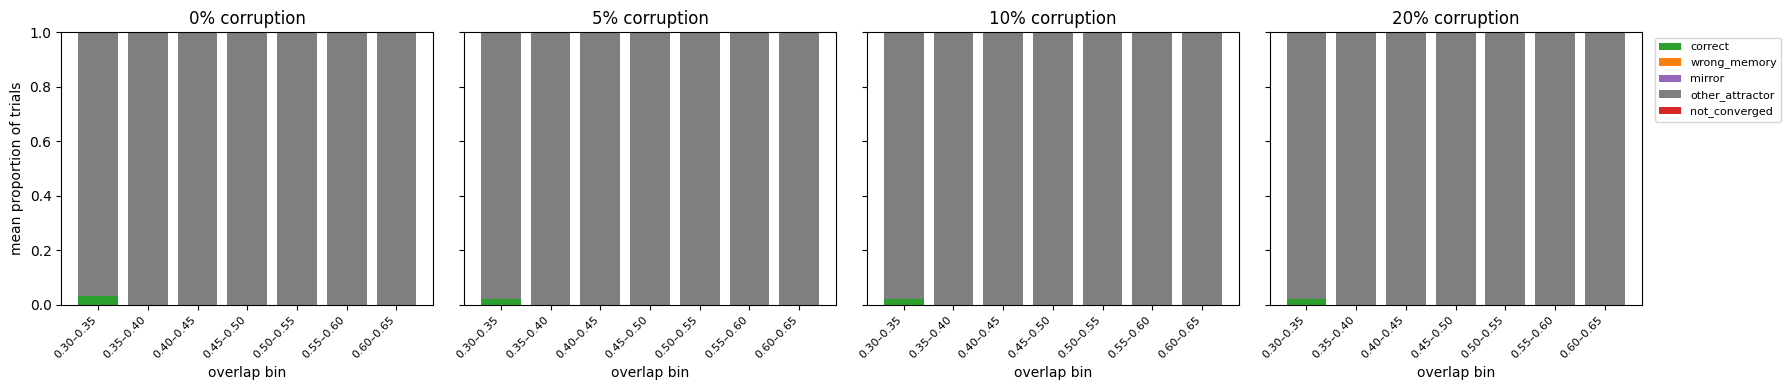

,0%,5%,10%,20%
correct,0.005,0.003,0.003,0.003
wrong_memory,0.000,0.000,0.000,0.000
mirror,0.000,0.000,0.000,0.000
other_attractor,0.995,0.997,0.997,0.997
not_converged,0.000,0.000,0.000,0.000


In [13]:
colors = {"correct": "tab:green", "wrong_memory": "tab:orange", "mirror": "tab:purple",
          "other_attractor": "tab:gray", "not_converged": "tab:red"}

fig, axes = plt.subplots(1, len(LEVELS), figsize=(18, 4), sharey=True)
for ax, level, title in zip(axes, LEVELS, ["0%", "5%", "10%", "20%"]):
    bottom = np.zeros(n_bins)
    for cat in CATEGORIES:
        vals = group_df.groupby("bin")[f"{cat}_{int(level*100)}"].mean().reindex(range(n_bins)).values
        ax.bar(range(n_bins), vals, bottom=bottom, color=colors[cat], label=cat)
        bottom += vals
    ax.set_xticks(range(n_bins)); ax.set_xticklabels(bin_labels, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{title} corruption"); ax.set_xlabel("overlap bin")
axes[0].set_ylabel("mean proportion of trials")
axes[-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Same numbers as a table: overall proportion of each outcome per level (mean over groups)
breakdown = pd.DataFrame({f"{int(l*100)}%": [group_df[f"{c}_{int(l*100)}"].mean() for c in CATEGORIES]
                          for l in LEVELS}, index=CATEGORIES)
breakdown.round(3)

### Secondary measure: how close do failed retrievals get?

Exact accuracy is all-or-nothing. The group mean of the **final overlap with the target** shows whether failures are near misses (m close to 1) or far from the target.
This is descriptive only. A high overlap is **not** counted as retrieval.

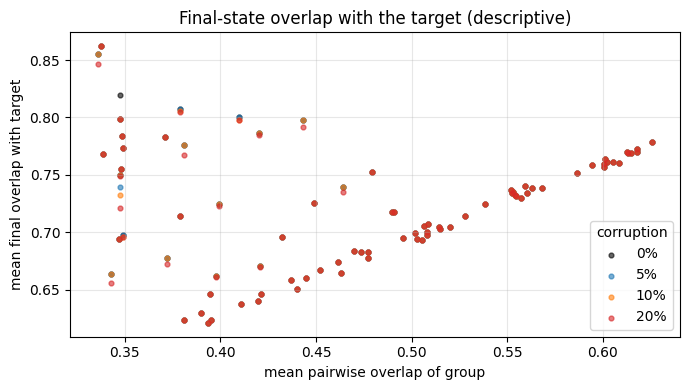

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
for level, c in zip(LEVELS, ["k", "tab:blue", "tab:orange", "tab:red"]):
    ax.scatter(group_df.mean_overlap, group_df[f"mean_final_overlap_{int(level*100)}"], s=12, alpha=0.6,
               color=c, label=f"{int(level*100)}%")
ax.set_xlabel("mean pairwise overlap of group"); ax.set_ylabel("mean final overlap with target")
ax.set_title("Final-state overlap with the target (descriptive)")
ax.legend(title="corruption"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Hand-picked groups (reported separately, not in any statistic)

In [15]:
hp_cols = ["group_id", "mean_overlap", "digits", "n_stable"] + level_cols + \
          [f"{c}_20" for c in ["wrong_memory", "mirror", "other_attractor", "not_converged"]]
hp_df[hp_cols].round(3)

,group_id,mean_overlap,digits,n_stable,correct_0,correct_5,correct_10,correct_20,wrong_memory_20,mirror_20,other_attractor_20,not_converged_20
0,hand_LOW,0.292,4 2 9 7 6,1,0.2,0.1,0.07,0.02,0.0,0.0,0.98,0.0
1,hand_HIGH,0.657,1 8 2 3 5,0,0.0,0.0,0.00,0.00,0.0,0.0,1.00,0.0


## 9. Summary (results only; interpretation comes later)

The tables and plots above are the results. For the write-up, keep these limits in mind:
- **Unit of analysis:** groups (n = 84). Trials are averaged within each group first.
- **Independence:** images are reused across groups, so groups are not fully independent and the confidence intervals are somewhat optimistic.
- **Scope:** groups were drawn only from the **typical-image subset** (476 of 946 images, defined in section 2) and always contain 5 different digits.
- **Association, not causation:** group overlap varies together with digit composition and other image properties.
- **Exact criterion:** a trial counts as retrieval only if it reproduces the stored image pixel for pixel. Blends and near misses are reported separately (`other_attractor`, final overlap).